<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  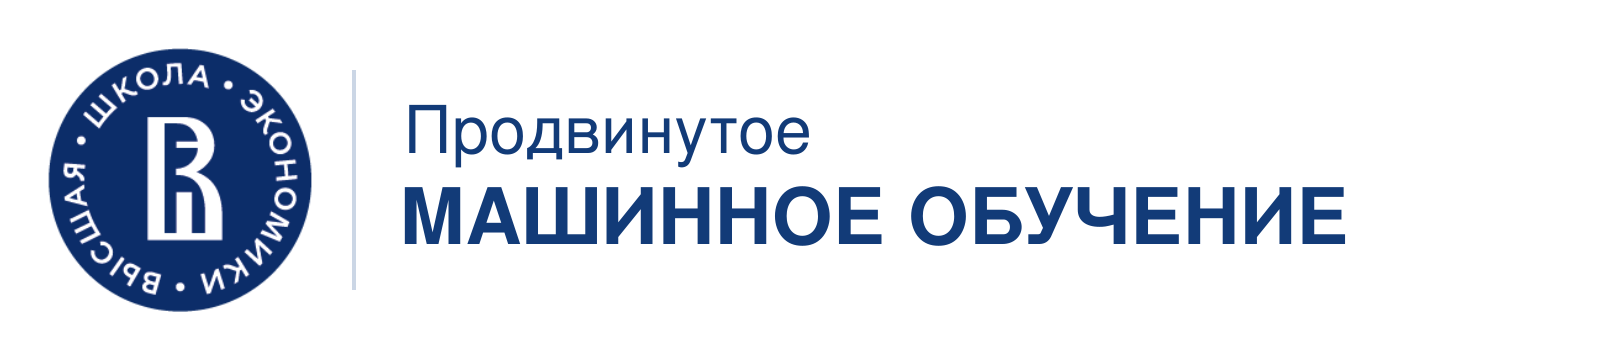

# Семинар №6
## Основные методы оценки важности признаков для ML моделей
### Credits for the seminar: [ML курс Евгения Соколова](https://github.com/esokolov/ml-course-hse/blob/master/2025-fall/seminars/sem11-xai.ipynb)
</div>


## **Подготовительная часть**
В этом ноутбуке разберем на практике изученные методы.

Цель на протяжении всей практической части, понять *от чего зависит целевая переменная на основе построенной модели*. Будем работать с данными **World Happiness Report** за 2018 и 2019 годы. В этих данных собраны показатели счастья по странам и возможные факторы, влияющие на уровень счастья населения.

[Ссылка на оригинальный датасет](https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2021/code?datasetId=1222432&sortBy=voteCount&language=Python).


In [1]:
!pip install -qU shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.9/555.9 kB 9.6 MB/s eta 0:00:00


In [2]:
!pip install -qU lime fat-forensics[all]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.1/212.1 kB 10.6 MB/s eta 0:00:00


### **Подготовка данных**

In [3]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.inspection import partial_dependence, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error

In [4]:
!pip install catppuccin
import catppuccin
plt.style.use("mocha")

In [5]:
data_to_work = pd.read_csv('/content/world-happiness-report-2021.csv', index_col=[0])

data_to_work.reset_index(drop=True, inplace=True)
data_to_work.drop(['Regional indicator', 'upperwhisker', 'lowerwhisker', 'Standard error of ladder score', 'Ladder score in Dystopia'], axis=1, inplace=True)

data_to_work.drop([i for i in data_to_work.columns if 'Explained' in i], axis=1, inplace=True)

In [6]:
X = data_to_work.drop('Ladder score', axis=1)
y = data_to_work['Ladder score']

Здесь мы просто обучим модель, используя `MinMaxScaler`. Преобразование (масштабирование), осуществляется так:

1. Определяем желаемый диапазон признаков — обычно $(0, 1)$. Обозначим $x_{min} = 0, x_{max} = 1$:

2. Масштабируем данные по формуле:

$$X_{scaled} = \frac{X-min(X)}{max(X) - min(X)}*(x_{max} - x_{min} + x_{min})$$

In [7]:
feature_names = list(X.columns)

# Выберем признак для анализа
feature_idx = 1
feature_name = data_to_work.columns[feature_idx]

# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


# Масштабирование
sc = MinMaxScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [8]:
# Обучение модели
rf = RandomForestRegressor(random_state=42, max_depth=4)
rf.fit(X_train_sc, y_train)

#predictions = np.clip(tree.predict(X_test), 1, 5)
predictions_rf = rf.predict(X_test_sc)

mse_rf = mean_squared_error(y_test, predictions_rf)
print(f'Model MSE : {mse_rf}, rmse: {mse_rf**(1/2)}')

Model MSE : 0.16423934229005727, rmse: 0.4052645337184803


Модель обучена. Перейдем к интерпретации.

## **1. Интерпретация по определению**

Как мы изучили в теоретической части, деревья относятся к интерпретируемым моделям и глобальная важность признака в них может быть вычислена как:
$$
    I_k = {w_k \cdot impurity_k - w_{left(k)} \cdot impurity_{left} - w_{right(k)} \cdot impurity_{right}}.
$$

для каждого узла $N_k$, где
* $w_k$ — доля наблюдений в узле от исходных данных,
* $impurity_k$ — мера загрязнённости (например, индекс Джини или энтропия),
* $w_{left(k)}, w_{right(k)}$ и $impurity_{left}, impurity_{right}$ — аналогичные величины для дочерних узлов.

А общая важность признака может быть вычислена как сумма по всем узлам, где он использовался, нормированная на общую важность всех признаков:

$$
    FeatureImportance(f_k) = \frac{\sum_{N_k: f=f_k} I_k}{\sum_{j} \sum_{N_k} I_k}.
$$


Случайный лес (Random Forest) может быть представлен как сумма решений деревьев. Следовательно, мы можем расширить древесную важность для леса, используя суммирование важности признака по всем деревьям и нормировку на общую важность признаков по деревьям.

Такая встроенная важность реализована во всех деревесных алгоритмах sklearn и доступна через feature importances. Посмотрим, как она выглядит.

<BarContainer object of 7 artists>

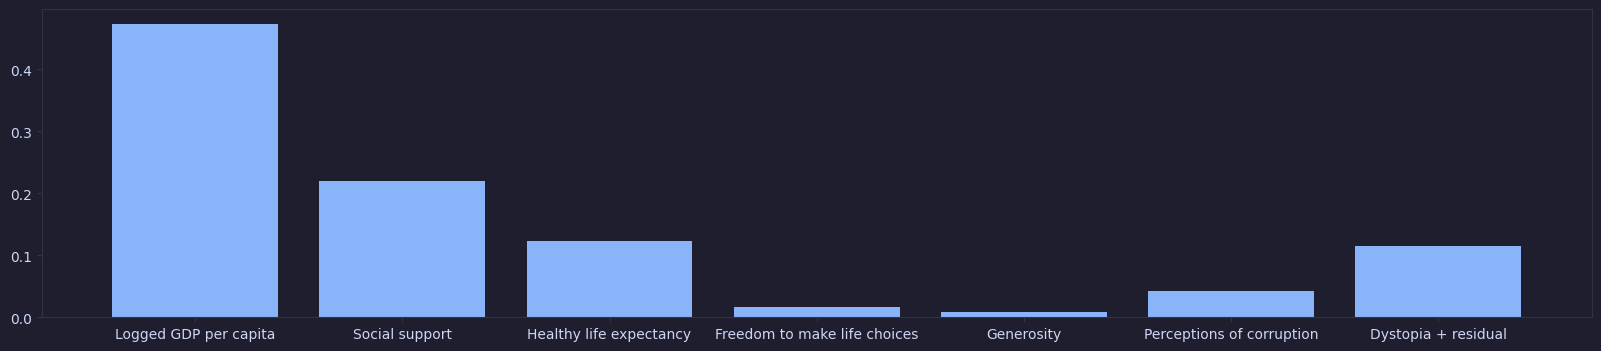

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(20, 4))
ax.bar(feature_names, rf.feature_importances_)

Посмотрим на интерпретацию другими методами.

## **1. Plot-based методы**

Название plot-based для класса методов, с которыми мы ознакомимся ниже, не является строгим или формальным. Оно просто скорее смысл методов — наиболее информативная их часть сосредоточена в графической оценке.

### **1. 1. ICE**

Кривые ICE относятся к локальным методам и показывают, как меняется прогноз модели с изменением конкретного признака в некотором наборе $X_{test}$. Они реализованы в `sklearn`, так что этот простой инструмент оценки влияния признаков всегда под рукой.

**Построение:**

1. Зафиксируем множество $X_{test}$ и некоторый признак $j$. Пусть  $j$ имеет $m$ уникальных значений $[j_1, j_2, ..., j_m]$.

2. Исходный датасет  $X_{test}$ дублируем  $m$ раз: $$X'_1, X'_2, ..., X'_m,$$ так, что для датасета $X'_i$ значение признака $j$ есть $j_i$;

3. На каждом $X'_i$ рассчитываем прогноз модели $f(X'_i)$&

4. На графике строим линии для каждого объекта, показывающие как прогноз (ось $y$) меняется при изменении признака (ось $x$);

ICE реализован в sklearn. Воспользуемся им.

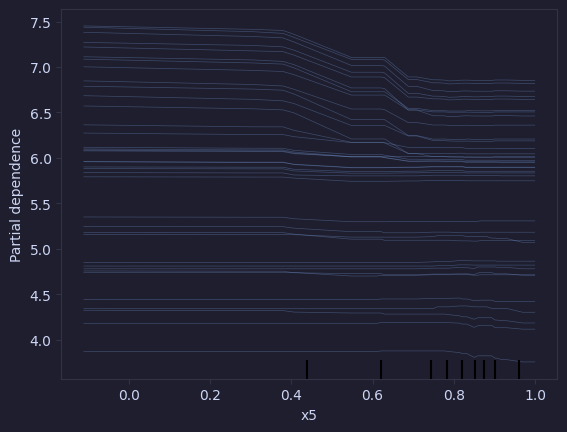

In [10]:
feature_idx = 5
model = rf

# Чуть более удобный способ
PartialDependenceDisplay.from_estimator(model, X_test_sc, [feature_idx],
   kind='individual')

Мы видим, что увеличение признака $j=5$ уменьшает прогноз модели. Согласно смыслу данных — чем больше значение признака `Perceptions of corruption` тем ниже ожидаемый индекс счастья.

Хотя ICE очень доступны и понятны, они обладают следующими минусами:

- Построение ICE использует предположение о независимости признаков;
- В случае большого количества объектов в наборе данных график ICE оказывается нечитаемым. Здесь также можно отметить, что иногда ICE становится читаемее и информативнее, если раскрашивать кривые по, например, классам какого-то признака.
-ICE не дает централизованной оценки, которую можно измерить. У этой проблемы есть решение — рассмотрение ICE в паре c PDP.

### **1. 2. PDP**

Partial Dependence plot является логическим продолжением ICE, а именно — усредняет его оценку. Это глобальная интерпретация и она также реализована в sklearn, в том числе в двумерном виде.


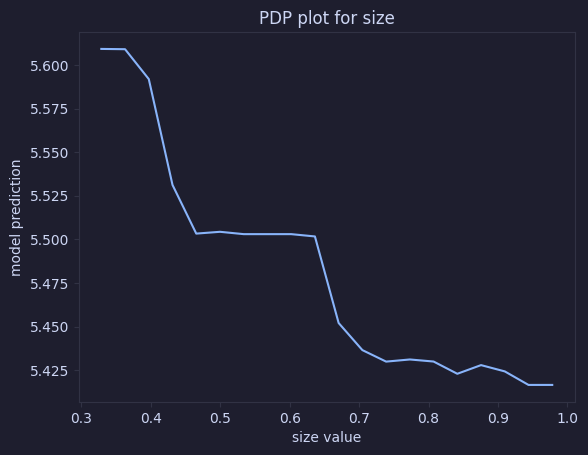

In [11]:
from sklearn.inspection import partial_dependence
from sklearn.inspection import PartialDependenceDisplay

results = partial_dependence(rf, X_test_sc, [5], grid_resolution=20, kind='average') # смотрим на тот же признак
#results = partial_dependence(tree, X_test, [0], grid_resolution=20, kind='individual') == ICE

results
plt.plot(results['grid_values'][0], results['average'][-1])

plt.title('PDP plot for size')
plt.xlabel('size value')
plt.ylabel('model prediction');

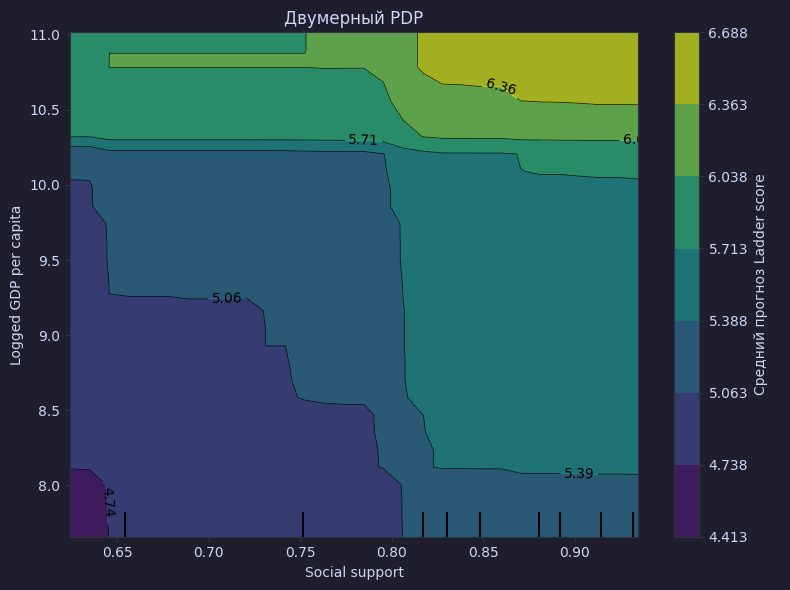

In [12]:
# используем уже обученные scaler и лес.
# подаем исходные данные: pipeline сам выполнит масштабирование перед прогнозом.
model = Pipeline([
    ("scaler", sc),
    ("forest", rf),
])

fig, ax = plt.subplots(figsize=(8, 6))

disp = PartialDependenceDisplay.from_estimator(
    model,
    X_test,
    features=[("Social support", "Logged GDP per capita")], # несколько фичей
    kind="average",
    method="brute",
    grid_resolution=30,
    contour_kw={"cmap": "viridis"},
    ax=ax,
)

pdp_ax = disp.axes_[0, 0]
pdp_ax.set_aspect("auto")
pdp_ax.set_title("Двумерный PDP")
pdp_ax.set_xlabel("Social support")
pdp_ax.set_ylabel("Logged GDP per capita")

fig.colorbar(
    disp.contours_[0, 0],
    ax=pdp_ax,
    label="Средний прогноз Ladder score",
)

plt.tight_layout()
plt.show()

Полностью прямые линии говорят, что взаимодействия нет (либо один признак вообще не имеет влияния в модели). Важно отметить, что
- partial dependence никак не учитывает распределение признака по группам. Если набор данных разделен на два класса, и для одного прогноз растет, а для другого — падает мы, в результате усреднения, получим нулевое влияние.
- partial dependence действует из предположения независимости признаков, что тоже часто оказывается некорректным для реальных данных.

### **1. 3. Accumulated Local Effects (ALE)**

Заключительный из основных графических методов — ALE. Он был предложен в 2019 для решения недостатков графиков частичной зависимости, а именно решения проблемы чувствительности к мультиколлинеарным признакам. Он уже не реализован в `sklearn` и нужно подтягивать дополнительные библиотеки.  



In [13]:
!pip install -qU pyALE;

INFO:PyALE._ALE_generic:Continuous feature detected.
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


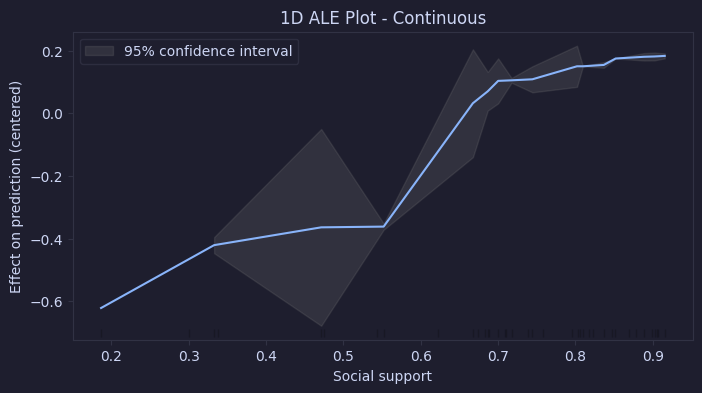

In [14]:
from PyALE import ale

## 1D - continuous - no CI
ale_eff = ale(
    X=pd.DataFrame(X_test_sc, columns=feature_names), model=rf, feature=['Social support'], grid_size=15,
)

Здесь мы также можем сразу смотреть на доверительный интервал со следующей интерпретацией:

$\theta$ — важность признака по ALE

$[\theta_1, \theta_2]$ —  с вероятностью 95% истинное значение важности лежит в этом интервале.

### **Сравнение подходов**

Как видите, в рамках одного алгоритма и простых данных все 3 подхода дают сопоставимый результат. Практический рецепт примерно такой — если в данных есть мультиколлинеарность — следует брать ALE, в остальном — достаточно комбинации ICE (чтобы проверить, нет ли объектов, на которых поведение прогноза не такое, на других) + PDP.


## **2. Permutation importances**

Теперь перейдем к методам, дающим коэффициенты. Базовый (и также доступный в `sklearn`) — permutation importances, гд важность признака  есть:

$$f_i=e_{orig} - \frac{1}{K}\sum\limits_{k=1}^Ke_{perm, k}$$

где $K$ — число перестановок, $e_{orig}, e_{perm}$ — ошибки прогноза модели на тестовом наборе данных.

In [15]:
from sklearn.inspection import permutation_importance

perm_results = permutation_importance(rf,
                                      X_train_sc,
                                      y_train,
                                      scoring='neg_mean_squared_error',
                                      n_repeats=10,
                                      random_state=17)
permutation_imp_data = pd.DataFrame(perm_results.importances_mean, columns=['importances'], index=X_train.columns)
permutation_imp_data['importances_std'] = perm_results.importances_std

permutation_imp_data

,importances,importances_std
Logged GDP per capita,0.457793,0.055321
Social support,0.182102,0.013705
Healthy life expectancy,0.092529,0.009273
Freedom to make life choices,0.015739,0.001864
Generosity,0.001925,0.001028
Perceptions of corruption,0.032734,0.003756
Dystopia + residual,0.219742,0.020421


Стандартные отклонения тоже полезно анализировать. Высокие значения std сигнализируют о нестабильности вклада признака. Это может быть вызвано корреляцией с другими признаками, слабой информативностью или спецификовй модели (например, неравномерное использование признака в деревьях леса). Но здесь у нас относительно небольшие отклонения.

## **3. SHAP**

Значения Шепли как практический инструмент решают три проблемы сразу:
- оценка локального влияния признака на прогноз;
- оценка глобального влияния признаков;
- оценка взаимодействия признаков;


In [19]:
import shap
#Локальное объяснение с shap

shap.initjs()
explainer = shap.TreeExplainer(rf, feature_names=feature_names)
shap_values = explainer(X_train_sc)

X_train_sc_df = pd.DataFrame(X_train_sc, columns=feature_names)

# Визуализируем прогнозы для 5-го объекта в тренировочных данных, отталкиваясь от ср арифметичекого по всей выборке (base value)
shap.plots.force(shap_values[5, :])

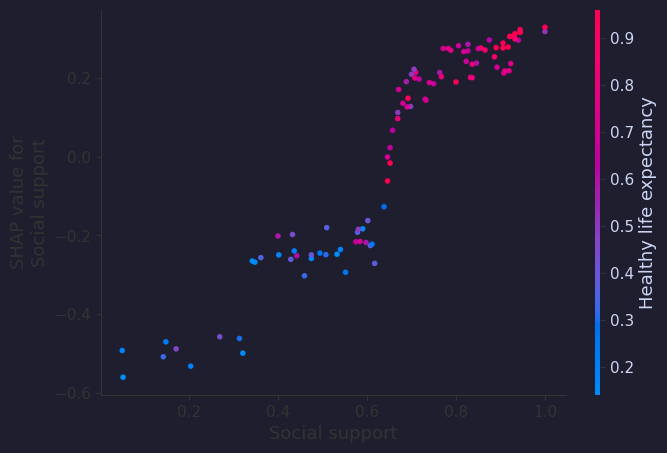

In [20]:
# оценка взаимодействия

shap.dependence_plot("Social support", shap_values.values[:100], X_train_sc_df[:100], interaction_index="Healthy life expectancy")

In [21]:
# глобальное поведение через force plot
shap.initjs()

#Посмотрим на график для первых 100 объектов тренировочного набора данных
shap.plots.force(shap_values[:100])

На графике — наблюдения, отсортированные в выбранном порядке (панель сверху). По умолчанию наблюдения остортированы по близости друг к другу (и по оси x — номер наблюдения в отсортированном ряду), а по оси y располагается прогноз модели.

Для y отображения можно выбирать различные признаки — и тогда будет видно, конкретный признак менял output модели.

Для x можно выбирать
- выходное значение (сортировка объектов по прогнозу модели)
- признаки — сортировка по значению признака
- порядковая сортировка (просто по порядку в выборке)

И из этого комбинировать различные графики для анализа.

## **4. LIME**

В завершение, посмотрим на локальную интрпретацию того же объекта с LIME.

In [24]:
from lime.lime_tabular import LimeTabularExplainer #посмотрим, что дает библиотечная реализация


data_point = X_test_sc[5, :]
explainer = LimeTabularExplainer(X_train_sc,
                                # class_names=iris_target_names,
                                 feature_names=feature_names,
                                 kernel_width=np.sqrt(len(feature_names)) * 0.75,
                                 verbose=False,
                                 mode='regression',
                                 discretize_continuous=False,
                                 sample_around_instance=False)

exp = explainer.explain_instance(data_point, rf.predict, top_labels=1)
exp.show_in_notebook()

In [23]:
shap.initjs()
shap.plots.force(shap_values[5, :])

Как видите, в данном примере коэффициенты интерпретации по SHAP и LIME оказались схожи. Однако в общем случае это не обязательно так: разные методы могут давать разные объяснения для одной и той же модели. Выбор инструмента зависит от задачи:

- LIME — работает быстрее, подходит для быстрых экспериментов и больших наборов данных, но результаты могут быть менее устойчивыми.
- SHAP — вычислительно дороже, зато даёт более строгую и согласованную интерпретацию.

На практике стоит помнить: интерпретация — это ещё один слой анализа, а не абсолютная истина. Поэтому при работе с реальными данными важно не только применять методы (не один!) объяснения, но и сопоставлять их результаты с предметной областью.